In [2]:
import os
import pandas as pd
from dotenv import load_dotenv
from supabase import create_client

# Load variables from .env
load_dotenv()

SUPABASE_URL = os.getenv("SUPABASE_URL")
SUPABASE_SERVICE_KEY = os.getenv("SUPABASE_SERVICE_KEY")

# Check that they loaded
if not SUPABASE_URL:
    raise ValueError("SUPABASE_URL was not found in .env")

if not SUPABASE_SERVICE_KEY:
    raise ValueError("SUPABASE_SERVICE_KEY was not found in .env")

# Create Supabase client
supabase = create_client(
    SUPABASE_URL,
    SUPABASE_SERVICE_KEY
)

print("Supabase client created successfully.")

Supabase client created successfully.


In [3]:
import pandas as pd

response = (
    supabase
    .table("ml_order_features")
    .select("*")
    .limit(5)
    .execute()
)

df_sample = pd.DataFrame(response.data)

print(f"Rows returned: {len(df_sample)}")
df_sample

Rows returned: 5


,feature_id,order_id,distributor_id,product_id,warehouse_id,shipping_mode,shipping_mode_encoded,order_item_quantity,order_item_total,month,is_peak_season,order_region,profit_ratio,label_delay_days,label_late_risk,created_at
0,1,1,10507,1181,9,Standard Class,1,1,314.64,1,False,Southeast Asia,0.29,-1,0,2026-10-04T18:39:56.891811+00:00
1,2,2,10507,1181,9,Standard Class,1,1,311.36,1,False,South Asia,-0.80,1,1,2026-10-04T18:39:56.891811+00:00
2,3,3,10507,1181,9,Standard Class,1,1,309.72,1,False,South Asia,-0.80,0,0,2026-10-04T18:39:56.891811+00:00
3,4,4,10509,1181,9,Standard Class,1,1,304.81,1,False,Oceania,0.08,-1,0,2026-10-04T18:39:56.891811+00:00
4,5,5,10508,1181,9,Standard Class,1,1,298.25,1,False,Oceania,0.45,-2,0,2026-10-04T18:39:56.891811+00:00


In [4]:
def load_table_in_batches(table_name, batch_size=1000):
    all_rows = []
    start = 0

    while True:
        end = start + batch_size - 1

        response = (
            supabase
            .table(table_name)
            .select("*")
            .range(start, end)
            .execute()
        )

        rows = response.data

        if not rows:
            break

        all_rows.extend(rows)

        print(f"Loaded {len(all_rows):,} rows...")

        if len(rows) < batch_size:
            break

        start += batch_size

    return pd.DataFrame(all_rows)

In [5]:
df_features = load_table_in_batches("ml_order_features")

print("Total rows:", len(df_features))
print("Shape:", df_features.shape)

Loaded 1,000 rows...
Loaded 2,000 rows...
Loaded 3,000 rows...
Loaded 4,000 rows...
Loaded 5,000 rows...
Loaded 6,000 rows...
Loaded 7,000 rows...
Loaded 8,000 rows...
Loaded 9,000 rows...
Loaded 10,000 rows...
Loaded 11,000 rows...
Loaded 12,000 rows...
Loaded 13,000 rows...
Loaded 14,000 rows...
Loaded 15,000 rows...
Loaded 16,000 rows...
Loaded 17,000 rows...
Loaded 18,000 rows...
Loaded 19,000 rows...
Loaded 20,000 rows...
Loaded 21,000 rows...
Loaded 22,000 rows...
Loaded 23,000 rows...
Loaded 24,000 rows...
Loaded 25,000 rows...
Loaded 26,000 rows...
Loaded 27,000 rows...
Loaded 28,000 rows...
Loaded 29,000 rows...
Loaded 30,000 rows...
Loaded 31,000 rows...
Loaded 32,000 rows...
Loaded 33,000 rows...
Loaded 34,000 rows...
Loaded 35,000 rows...
Loaded 36,000 rows...
Loaded 37,000 rows...
Loaded 38,000 rows...
Loaded 39,000 rows...
Loaded 40,000 rows...
Loaded 41,000 rows...
Loaded 42,000 rows...
Loaded 43,000 rows...
Loaded 44,000 rows...
Loaded 45,000 rows...
Loaded 46,000 rows.

In [6]:
import pandas as pd

def load_ml_data(page_size=1000):
    all_rows = []
    start = 0

    while True:
        response = (
            supabase
            .table("ml_order_features")
            .select("*")
            .range(start, start + page_size - 1)
            .execute()
        )

        rows = response.data

        if not rows:
            break

        all_rows.extend(rows)

        print(f"Loaded {len(all_rows)} rows...")

        if len(rows) < page_size:
            break

        start += page_size

    return pd.DataFrame(all_rows)

In [7]:
df = load_ml_data(page_size=1000)

Loaded 1000 rows...
Loaded 2000 rows...
Loaded 3000 rows...
Loaded 4000 rows...
Loaded 5000 rows...
Loaded 6000 rows...
Loaded 7000 rows...
Loaded 8000 rows...
Loaded 9000 rows...
Loaded 10000 rows...
Loaded 11000 rows...
Loaded 12000 rows...
Loaded 13000 rows...
Loaded 14000 rows...
Loaded 15000 rows...
Loaded 16000 rows...
Loaded 17000 rows...
Loaded 18000 rows...
Loaded 19000 rows...
Loaded 20000 rows...
Loaded 21000 rows...
Loaded 22000 rows...
Loaded 23000 rows...
Loaded 24000 rows...
Loaded 25000 rows...
Loaded 26000 rows...
Loaded 27000 rows...
Loaded 28000 rows...
Loaded 29000 rows...
Loaded 30000 rows...
Loaded 31000 rows...
Loaded 32000 rows...
Loaded 33000 rows...
Loaded 34000 rows...
Loaded 35000 rows...
Loaded 36000 rows...
Loaded 37000 rows...
Loaded 38000 rows...
Loaded 39000 rows...
Loaded 40000 rows...
Loaded 41000 rows...
Loaded 42000 rows...
Loaded 43000 rows...
Loaded 44000 rows...
Loaded 45000 rows...
Loaded 46000 rows...
Loaded 47000 rows...
Loaded 48000 rows...
L

In [8]:
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

Total rows: 180519
Columns: ['feature_id', 'order_id', 'distributor_id', 'product_id', 'warehouse_id', 'shipping_mode', 'shipping_mode_encoded', 'order_item_quantity', 'order_item_total', 'month', 'is_peak_season', 'order_region', 'profit_ratio', 'label_delay_days', 'label_late_risk', 'created_at']


In [9]:
df_features.head()

,feature_id,order_id,distributor_id,product_id,warehouse_id,shipping_mode,shipping_mode_encoded,order_item_quantity,order_item_total,month,is_peak_season,order_region,profit_ratio,label_delay_days,label_late_risk,created_at
0,1,1,10507,1181,9,Standard Class,1,1,314.64,1,False,Southeast Asia,0.29,-1,0,2026-10-04T18:39:56.891811+00:00
1,2,2,10507,1181,9,Standard Class,1,1,311.36,1,False,South Asia,-0.80,1,1,2026-10-04T18:39:56.891811+00:00
2,3,3,10507,1181,9,Standard Class,1,1,309.72,1,False,South Asia,-0.80,0,0,2026-10-04T18:39:56.891811+00:00
3,4,4,10509,1181,9,Standard Class,1,1,304.81,1,False,Oceania,0.08,-1,0,2026-10-04T18:39:56.891811+00:00
4,5,5,10508,1181,9,Standard Class,1,1,298.25,1,False,Oceania,0.45,-2,0,2026-10-04T18:39:56.891811+00:00


In [10]:
df_features.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   feature_id             180519 non-null  int64  
 1   order_id               180519 non-null  int64  
 2   distributor_id         180519 non-null  int64  
 3   product_id             180519 non-null  int64  
 4   warehouse_id           180519 non-null  int64  
 5   shipping_mode          180519 non-null  str    
 6   shipping_mode_encoded  180519 non-null  int64  
 7   order_item_quantity    180519 non-null  int64  
 8   order_item_total       180519 non-null  float64
 9   month                  180519 non-null  int64  
 10  is_peak_season         180519 non-null  bool   
 11  order_region           180519 non-null  str    
 12  profit_ratio           180519 non-null  float64
 13  label_delay_days       180519 non-null  int64  
 14  label_late_risk        180519 non-null  int64  

In [11]:
df_orders = load_table_in_batches("orders")

print("Total orders:", len(df_orders))
print(df_orders[["order_id", "order_date"]].head())

Loaded 1,000 rows...
Loaded 2,000 rows...
Loaded 3,000 rows...
Loaded 4,000 rows...
Loaded 5,000 rows...
Loaded 6,000 rows...
Loaded 7,000 rows...
Loaded 8,000 rows...
Loaded 9,000 rows...
Loaded 10,000 rows...
Loaded 11,000 rows...
Loaded 12,000 rows...
Loaded 13,000 rows...
Loaded 14,000 rows...
Loaded 15,000 rows...
Loaded 16,000 rows...
Loaded 17,000 rows...
Loaded 18,000 rows...
Loaded 19,000 rows...
Loaded 20,000 rows...
Loaded 21,000 rows...
Loaded 22,000 rows...
Loaded 23,000 rows...
Loaded 24,000 rows...
Loaded 25,000 rows...
Loaded 26,000 rows...
Loaded 27,000 rows...
Loaded 28,000 rows...
Loaded 29,000 rows...
Loaded 30,000 rows...
Loaded 31,000 rows...
Loaded 32,000 rows...
Loaded 33,000 rows...
Loaded 34,000 rows...
Loaded 35,000 rows...
Loaded 36,000 rows...
Loaded 37,000 rows...
Loaded 38,000 rows...
Loaded 39,000 rows...
Loaded 40,000 rows...
Loaded 41,000 rows...
Loaded 42,000 rows...
Loaded 43,000 rows...
Loaded 44,000 rows...
Loaded 45,000 rows...
Loaded 46,000 rows.

In [12]:
df_orders[["order_id", "order_date"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   order_id    180519 non-null  int64
 1   order_date  180519 non-null  str  
dtypes: int64(1), str(1)
memory usage: 2.8 MB


In [13]:
df_orders = df_orders[["order_id", "order_date"]].copy()

In [14]:
df = df_features.merge(
    df_orders,
    on="order_id",
    how="inner"
)

print("Final rows:", len(df))
print("Final columns:", len(df.columns))

Final rows: 180519
Final columns: 17


In [15]:
df.head()

,feature_id,order_id,distributor_id,product_id,warehouse_id,shipping_mode,shipping_mode_encoded,order_item_quantity,order_item_total,month,is_peak_season,order_region,profit_ratio,label_delay_days,label_late_risk,created_at,order_date
0,1,1,10507,1181,9,Standard Class,1,1,314.64,1,False,Southeast Asia,0.29,-1,0,2026-10-04T18:39:56.891811+00:00,2018-01-31
1,2,2,10507,1181,9,Standard Class,1,1,311.36,1,False,South Asia,-0.80,1,1,2026-10-04T18:39:56.891811+00:00,2018-01-13
2,3,3,10507,1181,9,Standard Class,1,1,309.72,1,False,South Asia,-0.80,0,0,2026-10-04T18:39:56.891811+00:00,2018-01-13
3,4,4,10509,1181,9,Standard Class,1,1,304.81,1,False,Oceania,0.08,-1,0,2026-10-04T18:39:56.891811+00:00,2018-01-13
4,5,5,10508,1181,9,Standard Class,1,1,298.25,1,False,Oceania,0.45,-2,0,2026-10-04T18:39:56.891811+00:00,2018-01-13


In [16]:
print("Final rows:", len(df))

Final rows: 180519


In [17]:
df["order_date"] = pd.to_datetime(df["order_date"])

print("Earliest:", df["order_date"].min())
print("Latest:", df["order_date"].max())

Earliest: 2015-01-01 00:00:00
Latest: 2018-01-31 00:00:00


In [18]:
train = df[
    (df["order_date"] >= "2015-01-01") &
    (df["order_date"] <= "2017-09-30")
].copy()

val = df[
    (df["order_date"] >= "2017-10-01") &
    (df["order_date"] <= "2017-11-30")
].copy()

test = df[
    (df["order_date"] >= "2017-12-01") &
    (df["order_date"] <= "2018-01-31")
].copy()

In [19]:
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))
print("Total:", len(train) + len(val) + len(test))

Train: 171962
Validation: 4310
Test: 4247
Total: 180519


In [20]:
print(df.columns.tolist())

['feature_id', 'order_id', 'distributor_id', 'product_id', 'warehouse_id', 'shipping_mode', 'shipping_mode_encoded', 'order_item_quantity', 'order_item_total', 'month', 'is_peak_season', 'order_region', 'profit_ratio', 'label_delay_days', 'label_late_risk', 'created_at', 'order_date']


In [21]:
FEATURES = [
    "shipping_mode_encoded",
    "order_item_quantity",
    "order_item_total",
    "month",
    "is_peak_season",
    "order_region",
    "profit_ratio",
]

In [22]:
REGRESSION_TARGET = "label_delay_days"
CLASSIFICATION_TARGET = "label_late_risk"

In [23]:
df[FEATURES + [REGRESSION_TARGET, CLASSIFICATION_TARGET]].head()

,shipping_mode_encoded,order_item_quantity,order_item_total,month,is_peak_season,order_region,profit_ratio,label_delay_days,label_late_risk
0,1,1,314.64,1,False,Southeast Asia,0.29,-1,0
1,1,1,311.36,1,False,South Asia,-0.80,1,1
2,1,1,309.72,1,False,South Asia,-0.80,0,0
3,1,1,304.81,1,False,Oceania,0.08,-1,0
4,1,1,298.25,1,False,Oceania,0.45,-2,0


In [24]:
print(df["order_region"].unique())
print(df["order_region"].value_counts())

<StringArray>
[ 'Southeast Asia',      'South Asia',         'Oceania',    'Eastern Asia',
       'West Asia',    'West of USA ',      'US Center ',     'West Africa',
  'Central Africa',    'North Africa',  'Western Europe', 'Northern Europe',
 'Central America',       'Caribbean',   'South America',     'East Africa',
 'Southern Europe',     'East of USA',          'Canada', 'Southern Africa',
    'Central Asia',  'Eastern Europe',  'South of  USA ']
Length: 23, dtype: str
order_region
Central America    28341
Western Europe     27109
South America      14935
Oceania            10148
Northern Europe     9792
Southeast Asia      9539
Southern Europe     9431
Caribbean           8318
West of USA         7993
South Asia          7731
Eastern Asia        7280
East of USA         6915
West Asia           6009
US Center           5887
South of  USA       4045
Eastern Europe      3920
West Africa         3696
North Africa        3232
East Africa         1852
Central Africa      1677
Souther

In [25]:
df[FEATURES + [REGRESSION_TARGET, CLASSIFICATION_TARGET]].isna().sum()

shipping_mode_encoded    0
order_item_quantity      0
order_item_total         0
month                    0
is_peak_season           0
order_region             0
profit_ratio             0
label_delay_days         0
label_late_risk          0
dtype: int64

In [26]:
df[FEATURES + [REGRESSION_TARGET, CLASSIFICATION_TARGET]].dtypes

shipping_mode_encoded      int64
order_item_quantity        int64
order_item_total         float64
month                      int64
is_peak_season              bool
order_region                 str
profit_ratio             float64
label_delay_days           int64
label_late_risk            int64
dtype: object

### PREPROCESSING ###

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

NUMERIC_FEATURES = [
    "shipping_mode_encoded",
    "order_item_quantity",
    "order_item_total",
    "month",
    "is_peak_season",
    "profit_ratio",
]

CATEGORICAL_FEATURES = [
    "order_region",
]

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES
        ),
    ]
)

In [29]:
X_train = train[FEATURES].copy()
y_train_reg = train[REGRESSION_TARGET].copy()
y_train_cls = train[CLASSIFICATION_TARGET].copy()

X_val = val[FEATURES].copy()
y_val_reg = val[REGRESSION_TARGET].copy()
y_val_cls = val[CLASSIFICATION_TARGET].copy()

X_test = test[FEATURES].copy()
y_test_reg = test[REGRESSION_TARGET].copy()
y_test_cls = test[CLASSIFICATION_TARGET].copy()

In [30]:
for dataset in [X_train, X_val, X_test]:
    dataset["is_peak_season"] = dataset["is_peak_season"].astype(int)

In [31]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [32]:
print("Train shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (171962, 29)
Validation shape: (4310, 29)
Test shape: (4247, 29)


### REGRESSION TRAINNING ###

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

#### Linear Regression Model ####

In [34]:
reg_linear = LinearRegression()

reg_linear.fit(
    X_train_processed,
    y_train_reg
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](29,)","[ 0.46, 0. ,-0. ,..., 0.01, 0. , 0.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.1874
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,29


In [35]:
val_pred_linear = reg_linear.predict(X_val_processed)

In [36]:
mae = mean_absolute_error(y_val_reg, val_pred_linear)
rmse = np.sqrt(mean_squared_error(y_val_reg, val_pred_linear))
r2 = r2_score(y_val_reg, val_pred_linear)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  1.1414
RMSE: 1.4311
R²:   0.0885


#### Random Forest Model ####

In [37]:
from sklearn.ensemble import RandomForestRegressor

In [38]:
reg_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

In [39]:
reg_rf.fit(
    X_train_processed,
    y_train_reg
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [40]:
val_pred_rf = reg_rf.predict(X_val_processed)

In [41]:
mae_rf = mean_absolute_error(y_val_reg, val_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_val_reg, val_pred_rf))
r2_rf = r2_score(y_val_reg, val_pred_rf)

print(f"MAE:  {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R²:   {r2_rf:.4f}")

MAE:  0.9917
RMSE: 1.2737
R²:   0.2780


#### Gradient Boosting Model #### 

In [42]:
from sklearn.ensemble import HistGradientBoostingRegressor

In [43]:
X_train_dense = X_train_processed.toarray()
X_val_dense = X_val_processed.toarray()
X_test_dense = X_test_processed.toarray()

In [44]:
print(X_train_dense.shape)
print(X_val_dense.shape)
print(X_test_dense.shape)

(171962, 29)
(4310, 29)
(4247, 29)


In [45]:
reg_gb = HistGradientBoostingRegressor(
    max_iter=200,
    max_depth=8,
    learning_rate=0.05,
    random_state=42
)

reg_gb.fit(
    X_train_dense,
    y_train_reg
)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",8
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [46]:
val_pred_gb = reg_gb.predict(X_val_dense)

In [47]:
mae_gb = mean_absolute_error(y_val_reg, val_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_val_reg, val_pred_gb))
r2_gb = r2_score(y_val_reg, val_pred_gb)

print(f"MAE:  {mae_gb:.4f}")
print(f"RMSE: {rmse_gb:.4f}")
print(f"R²:   {r2_gb:.4f}")

MAE:  0.9884
RMSE: 1.2697
R²:   0.2824


### XG BOOST ###

In [48]:
from xgboost import XGBRegressor

In [49]:

reg_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [50]:
reg_xgb.fit(
    X_train_dense,
    y_train_reg
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [51]:
val_pred_xgb = reg_xgb.predict(X_val_dense)

In [52]:
mae_xgb = mean_absolute_error(y_val_reg, val_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_val_reg, val_pred_xgb))
r2_xgb = r2_score(y_val_reg, val_pred_xgb)

print(f"MAE:  {mae_xgb:.4f}")
print(f"RMSE: {rmse_xgb:.4f}")
print(f"R²:   {r2_xgb:.4f}")

MAE:  1.0089
RMSE: 1.2832
R²:   0.2671


### MEAN BASELINE ###

In [53]:
mean_delay = y_train_reg.mean()

mean_pred = np.full(len(y_val_reg), mean_delay)

mean_mae = mean_absolute_error(y_val_reg, mean_pred)
mean_rmse = np.sqrt(mean_squared_error(y_val_reg, mean_pred))
mean_r2 = r2_score(y_val_reg, mean_pred)

print(f"Training mean delay: {mean_delay:.4f}")
print(f"MAE:  {mean_mae:.4f}")
print(f"RMSE: {mean_rmse:.4f}")
print(f"R²:   {mean_r2:.4f}")

Training mean delay: 0.5653
MAE:  1.2084
RMSE: 1.4989
R²:   -0.0000



### Shipping mode Baseline ###

In [54]:
shipping_mode_means = (
    train.groupby("shipping_mode_encoded")["label_delay_days"]
    .mean()
)

print(shipping_mode_means)

shipping_mode_encoded
1   -0.004140
2    1.989888
3    1.000000
4    0.475944
Name: label_delay_days, dtype: float64


In [55]:
shipping_mode_pred = (
    val["shipping_mode_encoded"]
    .map(shipping_mode_means)
)

shipping_mode_mae = mean_absolute_error(
    y_val_reg,
    shipping_mode_pred
)

shipping_mode_rmse = np.sqrt(
    mean_squared_error(y_val_reg, shipping_mode_pred)
)

shipping_mode_r2 = r2_score(
    y_val_reg,
    shipping_mode_pred
)

print(f"MAE:  {shipping_mode_mae:.4f}")
print(f"RMSE: {shipping_mode_rmse:.4f}")
print(f"R²:   {shipping_mode_r2:.4f}")

MAE:  0.9810
RMSE: 1.2679
R²:   0.2845


In [56]:
### Removal of profir-ratio ###
FEATURES_NO_PROFIT = [
    "shipping_mode_encoded",
    "order_item_quantity",
    "order_item_total",
    "month",
    "is_peak_season",
    "order_region",
]

In [57]:
X_train_no_profit = train[FEATURES_NO_PROFIT].copy()
X_val_no_profit = val[FEATURES_NO_PROFIT].copy()

for dataset in [X_train_no_profit, X_val_no_profit]:
    dataset["is_peak_season"] = dataset["is_peak_season"].astype(int)

In [58]:
preprocessor_no_profit = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", [
            "shipping_mode_encoded",
            "order_item_quantity",
            "order_item_total",
            "month",
            "is_peak_season",
        ]),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), [
            "order_region",
        ]),
    ]
)

In [59]:
X_train_no_profit_processed = preprocessor_no_profit.fit_transform(
    X_train_no_profit
)

X_val_no_profit_processed = preprocessor_no_profit.transform(
    X_val_no_profit
)

X_train_no_profit_dense = X_train_no_profit_processed.toarray()
X_val_no_profit_dense = X_val_no_profit_processed.toarray()

In [60]:
reg_gb_no_profit = HistGradientBoostingRegressor(
    max_iter=200,
    max_depth=8,
    learning_rate=0.05,
    random_state=42
)

reg_gb_no_profit.fit(
    X_train_no_profit_dense,
    y_train_reg
)

val_pred_no_profit = reg_gb_no_profit.predict(
    X_val_no_profit_dense
)

In [61]:
mae_no_profit = mean_absolute_error(
    y_val_reg,
    val_pred_no_profit
)

rmse_no_profit = np.sqrt(
    mean_squared_error(y_val_reg, val_pred_no_profit)
)

r2_no_profit = r2_score(
    y_val_reg,
    val_pred_no_profit
)

print(f"MAE:  {mae_no_profit:.4f}")
print(f"RMSE: {rmse_no_profit:.4f}")
print(f"R²:   {r2_no_profit:.4f}")

MAE:  0.9880
RMSE: 1.2693
R²:   0.2829


In [62]:
### removal of order item total##
FEATURES_NO_TOTAL = [
    "shipping_mode_encoded",
    "order_item_quantity",
    "month",
    "is_peak_season",
    "order_region",
    "profit_ratio",
]


In [63]:
X_train_no_total = train[FEATURES_NO_TOTAL].copy()
X_val_no_total = val[FEATURES_NO_TOTAL].copy()

for dataset in [X_train_no_total, X_val_no_total]:
    dataset["is_peak_season"] = dataset["is_peak_season"].astype(int)

In [64]:
preprocessor_no_total = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", [
            "shipping_mode_encoded",
            "order_item_quantity",
            "month",
            "is_peak_season",
            "profit_ratio",
        ]),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), [
            "order_region",
        ]),
    ]
)

In [65]:
X_train_no_total_processed = preprocessor_no_total.fit_transform(
    X_train_no_total
)

X_val_no_total_processed = preprocessor_no_total.transform(
    X_val_no_total
)

X_train_no_total_dense = X_train_no_total_processed.toarray()
X_val_no_total_dense = X_val_no_total_processed.toarray()

In [66]:
reg_gb_no_total = HistGradientBoostingRegressor(
    max_iter=200,
    max_depth=8,
    learning_rate=0.05,
    random_state=42
)

reg_gb_no_total.fit(
    X_train_no_total_dense,
    y_train_reg
)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",8
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [67]:
val_pred_no_total = reg_gb_no_total.predict(
    X_val_no_total_dense
)

mae_no_total = mean_absolute_error(
    y_val_reg,
    val_pred_no_total
)

rmse_no_total = np.sqrt(
    mean_squared_error(y_val_reg, val_pred_no_total)
)

r2_no_total = r2_score(
    y_val_reg,
    val_pred_no_total
)

print(f"MAE:  {mae_no_total:.4f}")
print(f"RMSE: {rmse_no_total:.4f}")
print(f"R²:   {r2_no_total:.4f}")

MAE:  0.9877
RMSE: 1.2705
R²:   0.2816


In [68]:
test_shipping_mode_pred = (
    test["shipping_mode_encoded"]
    .map(shipping_mode_means)
)

test_shipping_mae = mean_absolute_error(
    y_test_reg,
    test_shipping_mode_pred
)

test_shipping_rmse = np.sqrt(
    mean_squared_error(y_test_reg, test_shipping_mode_pred)
)

test_shipping_r2 = r2_score(
    y_test_reg,
    test_shipping_mode_pred
)

print("Shipping Mode Baseline")
print(f"MAE:  {test_shipping_mae:.4f}")
print(f"RMSE: {test_shipping_rmse:.4f}")
print(f"R²:   {test_shipping_r2:.4f}")

Shipping Mode Baseline
MAE:  0.9803
RMSE: 1.2648
R²:   0.2812


In [69]:
test_pred_gb = reg_gb.predict(X_test_dense)

test_gb_mae = mean_absolute_error(
    y_test_reg,
    test_pred_gb
)

test_gb_rmse = np.sqrt(
    mean_squared_error(y_test_reg, test_pred_gb)
)

test_gb_r2 = r2_score(
    y_test_reg,
    test_pred_gb
)

print("HistGradientBoosting")
print(f"MAE:  {test_gb_mae:.4f}")
print(f"RMSE: {test_gb_rmse:.4f}")
print(f"R²:   {test_gb_r2:.4f}")

HistGradientBoosting
MAE:  0.9860
RMSE: 1.2651
R²:   0.2808


## CLASSIFICATION ##

In [70]:
print(y_train_cls.value_counts())
print()
print(y_train_cls.value_counts(normalize=True))

label_late_risk
1    94268
0    77694
Name: count, dtype: int64

label_late_risk
1    0.548191
0    0.451809
Name: proportion, dtype: float64


#### LOGISTIC REGRESSION ###

In [71]:
from sklearn.linear_model import LogisticRegression

clf_logistic = LogisticRegression(
    max_iter=1000,
    random_state=42
)

clf_logistic.fit(
    X_train_processed,
    y_train_cls
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [72]:
val_prob_logistic = clf_logistic.predict_proba(
    X_val_processed
)[:, 1]

In [73]:
val_pred_logistic = (
    val_prob_logistic >= 0.5
).astype(int)

In [74]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    confusion_matrix
)

roc_auc = roc_auc_score(
    y_val_cls,
    val_prob_logistic
)

pr_auc = average_precision_score(
    y_val_cls,
    val_prob_logistic
)

f1 = f1_score(
    y_val_cls,
    val_pred_logistic
)

cm = confusion_matrix(
    y_val_cls,
    val_pred_logistic
)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}")
print(f"F1:      {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)

ROC-AUC: 0.7072
PR-AUC:  0.7069
F1:      0.6746

Confusion Matrix:
[[1626  342]
 [ 976 1366]]


### Random forest classifier ###

In [75]:
from sklearn.ensemble import RandomForestClassifier

clf_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

clf_rf.fit(
    X_train_processed,
    y_train_cls
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [76]:
val_prob_rf = clf_rf.predict_proba(
    X_val_processed
)[:, 1]

val_pred_rf = (
    val_prob_rf >= 0.5
).astype(int)

In [77]:
roc_auc_rf = roc_auc_score(
    y_val_cls,
    val_prob_rf
)

pr_auc_rf = average_precision_score(
    y_val_cls,
    val_prob_rf
)

f1_rf = f1_score(
    y_val_cls,
    val_pred_rf
)

cm_rf = confusion_matrix(
    y_val_cls,
    val_pred_rf
)

print(f"ROC-AUC: {roc_auc_rf:.4f}")
print(f"PR-AUC:  {pr_auc_rf:.4f}")
print(f"F1:      {f1_rf:.4f}")

print("\nConfusion Matrix:")
print(cm_rf)

ROC-AUC: 0.7289
PR-AUC:  0.7915
F1:      0.6738

Confusion Matrix:
[[1637  331]
 [ 984 1358]]


### HistGradientBoosting ###

In [78]:
from sklearn.ensemble import HistGradientBoostingClassifier

clf_gb = HistGradientBoostingClassifier(
    max_iter=200,
    max_depth=8,
    learning_rate=0.05,
    random_state=42
)

clf_gb.fit(
    X_train_dense,
    y_train_cls
)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",8
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing value

In [79]:
val_prob_gb = clf_gb.predict_proba(
    X_val_dense
)[:, 1]

val_pred_gb = (
    val_prob_gb >= 0.5
).astype(int)

In [80]:
roc_auc_gb = roc_auc_score(
    y_val_cls,
    val_prob_gb
)

pr_auc_gb = average_precision_score(
    y_val_cls,
    val_prob_gb
)

f1_gb = f1_score(
    y_val_cls,
    val_pred_gb
)

cm_gb = confusion_matrix(
    y_val_cls,
    val_pred_gb
)

print(f"ROC-AUC: {roc_auc_gb:.4f}")
print(f"PR-AUC:  {pr_auc_gb:.4f}")
print(f"F1:      {f1_gb:.4f}")

print("\nConfusion Matrix:")
print(cm_gb)

ROC-AUC: 0.7310
PR-AUC:  0.7964
F1:      0.6610

Confusion Matrix:
[[1713  255]
 [1060 1282]]


### XGBOOST ###

In [81]:
import xgboost as xgb

clf_xgb = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    random_state=42,
    n_jobs=-1
)

clf_xgb.fit(
    X_train_dense,
    y_train_cls
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [82]:
val_prob_xgb = clf_xgb.predict_proba(
    X_val_dense
)[:, 1]

val_pred_xgb = (
    val_prob_xgb >= 0.5
).astype(int)

In [83]:
roc_auc_xgb = roc_auc_score(
    y_val_cls,
    val_prob_xgb
)

pr_auc_xgb = average_precision_score(
    y_val_cls,
    val_prob_xgb
)

f1_xgb = f1_score(
    y_val_cls,
    val_pred_xgb
)

cm_xgb = confusion_matrix(
    y_val_cls,
    val_pred_xgb
)

print(f"ROC-AUC: {roc_auc_xgb:.4f}")
print(f"PR-AUC:  {pr_auc_xgb:.4f}")
print(f"F1:      {f1_xgb:.4f}")

print("\nConfusion Matrix:")
print(cm_xgb)

ROC-AUC: 0.7342
PR-AUC:  0.7994
F1:      0.6613

Confusion Matrix:
[[1632  336]
 [1019 1323]]


In [84]:
###Testing XGBOOST##
test_prob_xgb = clf_xgb.predict_proba(
    X_test_dense
)[:, 1]

test_pred_xgb = (
    test_prob_xgb >= 0.5
).astype(int)


In [85]:
test_roc_auc_xgb = roc_auc_score(
    y_test_cls,
    test_prob_xgb
)

test_pr_auc_xgb = average_precision_score(
    y_test_cls,
    test_prob_xgb
)

test_f1_xgb = f1_score(
    y_test_cls,
    test_pred_xgb
)

test_cm_xgb = confusion_matrix(
    y_test_cls,
    test_pred_xgb
)

print(f"ROC-AUC: {test_roc_auc_xgb:.4f}")
print(f"PR-AUC:  {test_pr_auc_xgb:.4f}")
print(f"F1:      {test_f1_xgb:.4f}")

print("\nConfusion Matrix:")
print(test_cm_xgb)

ROC-AUC: 0.7219
PR-AUC:  0.7964
F1:      0.6662

Confusion Matrix:
[[1610  270]
 [1050 1317]]


## SHAP ##

In [86]:
import shap

c:\Users\Sheriffdeen\c1-optimizers-project-3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [87]:
explainer = shap.TreeExplainer(reg_gb)

In [88]:
shap_values = explainer.shap_values(X_val_dense)

In [89]:
print(shap_values.shape)

(4310, 29)


In [90]:
explainer = shap.TreeExplainer(reg_gb)

shap_values = explainer.shap_values(X_val_dense)

print(shap_values.shape)

(4310, 29)


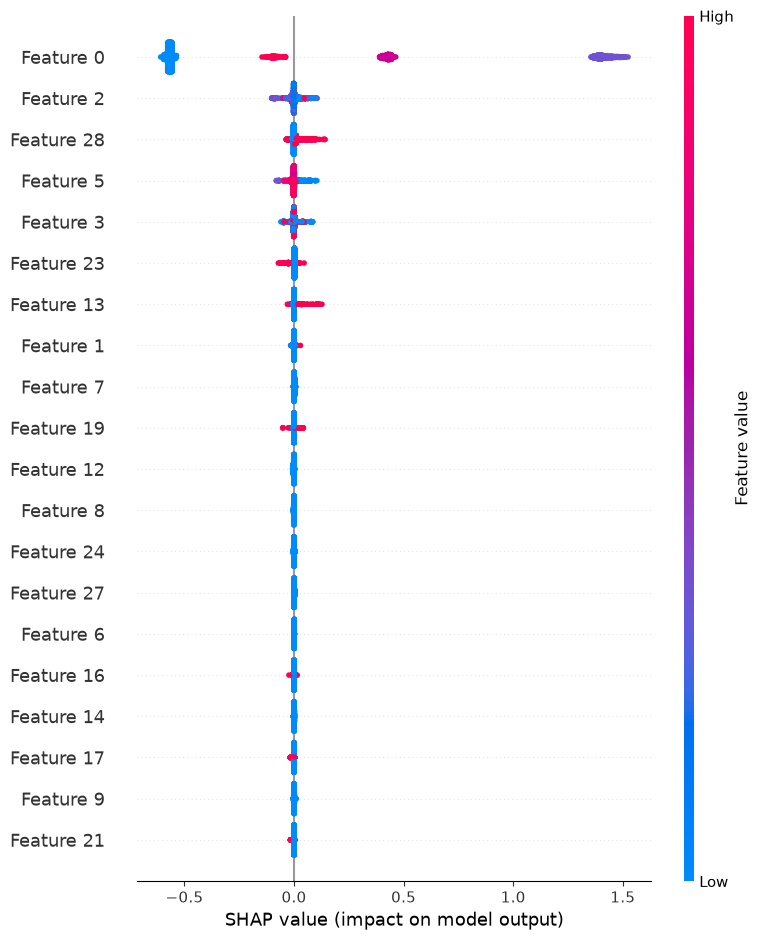

In [91]:
shap.summary_plot(
    shap_values,
    X_val_dense
)

In [92]:
import numpy as np

mean_abs_shap = np.abs(shap_values).mean(axis=0)

feature_importance = pd.DataFrame({
    "feature_index": range(len(mean_abs_shap)),
    "mean_abs_shap": mean_abs_shap
})

feature_importance = feature_importance.sort_values(
    "mean_abs_shap",
    ascending=False
)

print(feature_importance.head(10))

    feature_index  mean_abs_shap
0               0       0.684229
2               2       0.012751
28             28       0.007679
5               5       0.006521
3               3       0.006520
23             23       0.004390
13             13       0.002742
1               1       0.001252
7               7       0.001175
19             19       0.000991


In [93]:
np.abs(shap_values).mean(axis=0)

array([6.84228856e-01, 1.25202062e-03, 1.27507285e-02, 6.52036464e-03,
       0.00000000e+00, 6.52099523e-03, 6.08216527e-04, 1.17483267e-03,
       7.61908812e-04, 4.00461485e-04, 7.63439627e-05, 8.57961975e-06,
       8.71342350e-04, 2.74245269e-03, 4.96587691e-04, 9.94224560e-05,
       5.77135924e-04, 4.84916579e-04, 1.81684290e-04, 9.90956746e-04,
       1.27047646e-05, 1.89401816e-04, 1.19690808e-05, 4.39004331e-03,
       7.04432916e-04, 7.86664852e-05, 1.53101749e-04, 6.75541663e-04,
       7.67873928e-03])

In [94]:
feature_names = preprocessor.get_feature_names_out()

top_10 = feature_importance.head(10)

for _, row in top_10.iterrows():
    i = int(row["feature_index"])
    print(feature_names[i], "→", round(row["mean_abs_shap"], 4))

numeric__shipping_mode_encoded → 0.6842
numeric__order_item_total → 0.0128
categorical__order_region_Western Europe → 0.0077
numeric__profit_ratio → 0.0065
numeric__month → 0.0065
categorical__order_region_Southern Europe → 0.0044
categorical__order_region_Eastern Asia → 0.0027
numeric__order_item_quantity → 0.0013
categorical__order_region_Caribbean → 0.0012
categorical__order_region_South Asia → 0.001


## ML FLOW ##

In [95]:
import mlflow
import mlflow.sklearn

print(mlflow.__version__)

3.17.0


In [96]:
import os
from dotenv import load_dotenv

load_dotenv()

print("MLFLOW_TRACKING_URI:", os.getenv("MLFLOW_TRACKING_URI"))
print("MLFLOW_TRACKING_USERNAME:", os.getenv("MLFLOW_TRACKING_USERNAME"))
print("MLFLOW_TRACKING_PASSWORD:", "SET" if os.getenv("MLFLOW_TRACKING_PASSWORD") else "NOT SET")

MLFLOW_TRACKING_URI: None
MLFLOW_TRACKING_USERNAME: None
MLFLOW_TRACKING_PASSWORD: NOT SET


In [97]:
from dotenv import load_dotenv
import os

load_dotenv(override=True)

print(os.getenv("MLFLOW_TRACKING_URI"))
print(os.getenv("MLFLOW_TRACKING_USERNAME"))
print("Token:", "SET" if os.getenv("MLFLOW_TRACKING_PASSWORD") else "NOT SET")

https://dagshub.com/RunOut/runout-ml.mlflow
sheriffdeensalaudeen27
Token: SET


In [98]:
import mlflow
import os

mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI"))

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: https://dagshub.com/RunOut/runout-ml.mlflow


In [101]:
import os
from dotenv import load_dotenv
import mlflow

load_dotenv()

mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI"))

print("MLflow URI:", mlflow.get_tracking_uri())

MLflow URI: https://dagshub.com/RunOut/runout-ml.mlflow


In [102]:
mlflow.set_experiment("RunOut-M1")

with mlflow.start_run():
    mlflow.log_param("test", "connection")
    mlflow.log_metric("test_metric", 1.0)

print("MLflow test successful!")

2026/10/07 18:03:58 INFO mlflow.tracking.fluent: Experiment with name 'RunOut-M1' does not exist. Creating a new experiment.


MlflowException: API request to endpoint /api/2.0/mlflow/experiments/create failed with error code 403 != 200. Response body: ''

### Generating prediction ###

In [106]:
preprocessor
reg_gb
clf_xgb

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [107]:
reg_test_pred = reg_gb.predict(X_test_dense)

clf_test_prob = clf_xgb.predict_proba(X_test_dense)[:, 1]

print("Regression:", reg_test_pred[:5])
print("Risk:", clf_test_prob[:5])

Regression: [ 0.00731912 -0.0255211  -0.0255211   0.00731912  0.00731912]
Risk: [0.4009767  0.28120407 0.28120407 0.3783626  0.40679348]


In [108]:
X_all = df[FEATURES]

X_all_processed = preprocessor.transform(X_all)

# Convert to dense if needed
X_all_dense = (
    X_all_processed.toarray()
    if hasattr(X_all_processed, "toarray")
    else X_all_processed
)

print(X_all_dense.shape)

(180519, 29)


In [109]:
predicted_delay_days = reg_gb.predict(X_all_dense)

delay_risk_score = clf_xgb.predict_proba(X_all_dense)[:, 1]

print(predicted_delay_days.shape)
print(delay_risk_score.shape)

(180519,)
(180519,)


### SHAP EXPLAINER + DATABASE ###

In [110]:
explainer = shap.TreeExplainer(reg_gb)

In [111]:
shap_values_all = explainer.shap_values(X_all_dense)

print(shap_values_all.shape)

(180519, 29)


In [112]:
top5_shap_all = []

for row_idx in range(len(shap_values_all)):
    row_shap = shap_values_all[row_idx]

    top_indices = np.argsort(np.abs(row_shap))[-5:][::-1]

    explanation = []

    for idx in top_indices:
        explanation.append({
            "feature": feature_names[idx],
            "contribution": round(float(row_shap[idx]), 4)
        })

    top5_shap_all.append(explanation)

print(top5_shap_all[0])

[{'feature': 'numeric__shipping_mode_encoded', 'contribution': -0.5562}, {'feature': 'numeric__profit_ratio', 'contribution': -0.0031}, {'feature': 'numeric__month', 'contribution': -0.003}, {'feature': 'categorical__order_region_Caribbean', 'contribution': 0.0025}, {'feature': 'categorical__order_region_East of USA', 'contribution': -0.0023}]


In [113]:
predictions_df = pd.DataFrame({
    "order_id": df["order_id"].astype(int),
    "model_version": "m1-v1",
    "delay_risk_score": delay_risk_score,
    "predicted_delay_days": predicted_delay_days,
    "shap_explanation": top5_shap_all,
})

predictions_df.head()

,order_id,model_version,delay_risk_score,predicted_delay_days,shap_explanation
0,1,m1-v1,0.400977,0.007319,"[{'feature': 'numeric__shipping_mode_encoded',..."
1,2,m1-v1,0.281204,-0.025521,"[{'feature': 'numeric__shipping_mode_encoded',..."
2,3,m1-v1,0.281204,-0.025521,"[{'feature': 'numeric__shipping_mode_encoded',..."
3,4,m1-v1,0.378363,0.007319,"[{'feature': 'numeric__shipping_mode_encoded',..."
4,5,m1-v1,0.406793,0.007319,"[{'feature': 'numeric__shipping_mode_encoded',..."


In [114]:
from datetime import datetime, timezone

predictions_df["scored_at"] = datetime.now(timezone.utc)
predictions_df["as_of_date"] = pd.Timestamp.now().date()

print(predictions_df.shape)
predictions_df.head()

(180519, 7)


,order_id,model_version,delay_risk_score,predicted_delay_days,shap_explanation,scored_at,as_of_date
0,1,m1-v1,0.400977,0.007319,"[{'feature': 'numeric__shipping_mode_encoded',...",2026-10-07 17:32:05.028605+00:00,2026-10-07
1,2,m1-v1,0.281204,-0.025521,"[{'feature': 'numeric__shipping_mode_encoded',...",2026-10-07 17:32:05.028605+00:00,2026-10-07
2,3,m1-v1,0.281204,-0.025521,"[{'feature': 'numeric__shipping_mode_encoded',...",2026-10-07 17:32:05.028605+00:00,2026-10-07
3,4,m1-v1,0.378363,0.007319,"[{'feature': 'numeric__shipping_mode_encoded',...",2026-10-07 17:32:05.028605+00:00,2026-10-07
4,5,m1-v1,0.406793,0.007319,"[{'feature': 'numeric__shipping_mode_encoded',...",2026-10-07 17:32:05.028605+00:00,2026-10-07


In [115]:
feature_name_map = {
    "numeric__shipping_mode_encoded": "Shipping Mode",
    "numeric__order_item_quantity": "Order Quantity",
    "numeric__order_item_total": "Order Value",
    "numeric__month": "Month",
    "numeric__is_peak_season": "Peak Season",
    "numeric__profit_ratio": "Profit Ratio",
}


In [116]:
def clean_feature_name(name):
    if name in feature_name_map:
        return feature_name_map[name]

    if name.startswith("categorical__order_region_"):
        region = name.replace("categorical__order_region_", "")
        return f"Order Region: {region}"

    return name.replace("numeric__", "").replace("_", " ").title()


readable_shap = []

for row_shap in shap_values_all:
    top_indices = np.argsort(np.abs(row_shap))[-5:][::-1]

    explanation = []

    for idx in top_indices:
        contribution = float(row_shap[idx])

        explanation.append({
            "feature": clean_feature_name(feature_names[idx]),
            "contribution_days": round(contribution, 4),
            "impact": (
                "increases predicted delay"
                if contribution > 0
                else "decreases predicted delay"
            )
        })

    readable_shap.append(explanation)

In [117]:
predictions_df["shap_explanation"] = readable_shap

In [118]:
predictions_df[[
    "order_id",
    "predicted_delay_days",
    "delay_risk_score",
    "shap_explanation"
]].head(3)

,order_id,predicted_delay_days,delay_risk_score,shap_explanation
0,1,0.007319,0.400977,"[{'feature': 'Shipping Mode', 'contribution_da..."
1,2,-0.025521,0.281204,"[{'feature': 'Shipping Mode', 'contribution_da..."
2,3,-0.025521,0.281204,"[{'feature': 'Shipping Mode', 'contribution_da..."


In [119]:
from datetime import datetime, timezone

now = datetime.now(timezone.utc)

predictions_df["scored_at"] = now
predictions_df["as_of_date"] = now.date()

print(predictions_df.shape)

(180519, 7)


In [120]:
print(predictions_df.columns.tolist())

['order_id', 'model_version', 'delay_risk_score', 'predicted_delay_days', 'shap_explanation', 'scored_at', 'as_of_date']


In [121]:
# Prepare data for Supabase
upload_df = predictions_df.copy()

# Convert timestamps to strings
upload_df["scored_at"] = upload_df["scored_at"].astype(str)
upload_df["as_of_date"] = upload_df["as_of_date"].astype(str)

# Convert DataFrame to records
records = upload_df.to_dict(orient="records")

print("Total records:", len(records))

Total records: 180519


In [122]:
batch_size = 500

for start in range(0, len(records), batch_size):
    batch = records[start:start + batch_size]

    supabase.table("predictions").insert(batch).execute()

    print(f"Uploaded {min(start + batch_size, len(records)):,} / {len(records):,}")

Uploaded 500 / 180,519
Uploaded 1,000 / 180,519
Uploaded 1,500 / 180,519
Uploaded 2,000 / 180,519
Uploaded 2,500 / 180,519
Uploaded 3,000 / 180,519
Uploaded 3,500 / 180,519
Uploaded 4,000 / 180,519
Uploaded 4,500 / 180,519
Uploaded 5,000 / 180,519
Uploaded 5,500 / 180,519
Uploaded 6,000 / 180,519
Uploaded 6,500 / 180,519
Uploaded 7,000 / 180,519
Uploaded 7,500 / 180,519
Uploaded 8,000 / 180,519
Uploaded 8,500 / 180,519
Uploaded 9,000 / 180,519
Uploaded 9,500 / 180,519
Uploaded 10,000 / 180,519
Uploaded 10,500 / 180,519
Uploaded 11,000 / 180,519
Uploaded 11,500 / 180,519
Uploaded 12,000 / 180,519
Uploaded 12,500 / 180,519
Uploaded 13,000 / 180,519
Uploaded 13,500 / 180,519
Uploaded 14,000 / 180,519
Uploaded 14,500 / 180,519
Uploaded 15,000 / 180,519
Uploaded 15,500 / 180,519
Uploaded 16,000 / 180,519
Uploaded 16,500 / 180,519
Uploaded 17,000 / 180,519
Uploaded 17,500 / 180,519
Uploaded 18,000 / 180,519
Uploaded 18,500 / 180,519
Uploaded 19,000 / 180,519
Uploaded 19,500 / 180,519
Uploade